# Mô hình Hỗn hợp Gauss (GMM) & Thuật toán Kỳ vọng - Cực đại (EM)

K-Means mắc một sai lầm cơ bản: nó coi các cụm luôn có dạng hình cầu (hình tròn) và phân cụm "cứng" (một điểm chỉ thuộc về đúng 1 cụm). **Gaussian Mixture Models (GMM)** khắc phục điều này bằng cách phân cụm "mềm" dựa trên xác suất và cho phép các cụm có hình elip kéo dãn tùy ý.

**1. GMM (Gaussian Mixture Models):**
GMM giả định rằng dữ liệu được sinh ra từ sự pha trộn của $K$ phân phối Chuẩn (Gauss).
Xác suất để một điểm $x$ xuất hiện là tổng xác suất từ $K$ thành phần:
$$P(x) = \sum_{k=1}^K \pi_k \mathcal{N}(x | \mu_k, \Sigma_k)$$
*   $\pi_k$: Trọng số (tỷ lệ) của cụm $k$ (tổng các $\pi_k = 1$).
*   $\mu_k, \Sigma_k$: Kỳ vọng (tâm) và Ma trận hiệp phương sai (hình dáng elip) của cụm $k$.

**2. Thuật toán Expectation-Maximization (EM):**
GMM không thể giải trực tiếp bằng đạo hàm vì có biến ẩn (không biết điểm nào thuộc cụm nào). Thuật toán EM giải quyết bằng cách lặp lại 2 bước:
*   **Bước E (Expectation - Kỳ vọng):** Tính xác suất hậu nghiệm (trách nhiệm - responsibility $\gamma_{ik}$) mà cụm $k$ tạo ra điểm $x_i$:
    $$\gamma_{ik} = \frac{\pi_k \mathcal{N}(x_i | \mu_k, \Sigma_k)}{\sum_{j=1}^K \pi_j \mathcal{N}(x_i | \mu_j, \Sigma_j)}$$
*   **Bước M (Maximization - Cực đại hóa):** Cập nhật lại các tham số $\pi_k, \mu_k, \Sigma_k$ dựa trên các xác suất $\gamma_{ik}$ vừa tính được (thay vì dùng nhãn 0/1 cứng nhắc như K-Means). Quá trình này đảm bảo Log-Likelihood luôn tăng qua mỗi vòng lặp.

In [1]:
import numpy as np
from scipy.stats import multivariate_normal

class GMMScratch:
    """Mô hình Hỗn hợp Gauss tối ưu bằng thuật toán Expectation-Maximization (EM)."""
    def __init__(self, n_components=3, max_iters=100, tol=1e-4, random_state=42):
        self.k = n_components
        self.max_iters = max_iters
        self.tol = tol
        self.random_state = random_state
        self.means = None
        self.covs = None
        self.weights = None

    def fit(self, X: np.ndarray):
        X = np.asarray(X)
        n_samples, n_features = X.shape
        np.random.seed(self.random_state)
        
        # 1. Khởi tạo tham số
        # Tâm cụm (Means): Chọn ngẫu nhiên K điểm từ dữ liệu
        self.means = X[np.random.choice(n_samples, self.k, replace=False)]
        # Ma trận Hiệp phương sai (Covs): Khởi tạo là ma trận đơn vị (hình cầu chuẩn)
        self.covs = [np.eye(n_features) for _ in range(self.k)]
        # Trọng số (Weights/Priors): Chia đều cho K cụm
        self.weights = np.ones(self.k) / self.k
        
        log_likelihood_old = 0
        
        for iteration in range(self.max_iters):
            # ----------------------------------------------------
            # BƯỚC E (Expectation): Tính ma trận Trách nhiệm (Responsibilities)
            # ----------------------------------------------------
            resps = np.zeros((n_samples, self.k))
            for j in range(self.k):
                # Tính tử số: Prior * Likelihood (dùng scipy.stats để ổn định số học)
                resps[:, j] = self.weights[j] * multivariate_normal.pdf(
                    X, mean=self.means[j], cov=self.covs[j], allow_singular=True
                )
            
            # Tính Log-Likelihood tổng để kiểm tra hội tụ
            log_likelihood_new = np.sum(np.log(np.sum(resps, axis=1) + 1e-10))
            
            # Chuẩn hóa (chia cho mẫu số) để ra xác suất hậu nghiệm
            resps = resps / (np.sum(resps, axis=1, keepdims=True) + 1e-10)
            
            # Dừng sớm nếu Log-Likelihood không tăng đáng kể (Hội tụ)
            if np.abs(log_likelihood_new - log_likelihood_old) < self.tol:
                break
            log_likelihood_old = log_likelihood_new
            
            # ----------------------------------------------------
            # BƯỚC M (Maximization): Cập nhật tham số từ Responsibilities
            # ----------------------------------------------------
            N_k = np.sum(resps, axis=0) # Tổng xác suất (dân số ảo) của từng cụm
            
            for j in range(self.k):
                # Cập nhật Means (Kỳ vọng)
                self.means[j] = np.sum(resps[:, j:j+1] * X, axis=0) / N_k[j]
                
                # Cập nhật Covariances (Hiệp phương sai)
                diff = X - self.means[j]
                self.covs[j] = (resps[:, j:j+1] * diff).T @ diff / N_k[j]
                # Thêm epsilon (1e-6) vào đường chéo để tránh ma trận bị suy biến (Singular Matrix)
                self.covs[j].flat[::n_features+1] += 1e-6
                
            # Cập nhật Weights (Tỷ lệ trọng số)
            self.weights = N_k / n_samples
            
        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        # Gán nhãn cứng dựa trên xác suất cao nhất
        resps = np.zeros((X.shape[0], self.k))
        for j in range(self.k):
            resps[:, j] = self.weights[j] * multivariate_normal.pdf(X, self.means[j], self.covs[j], allow_singular=True)
        return np.argmax(resps, axis=1)

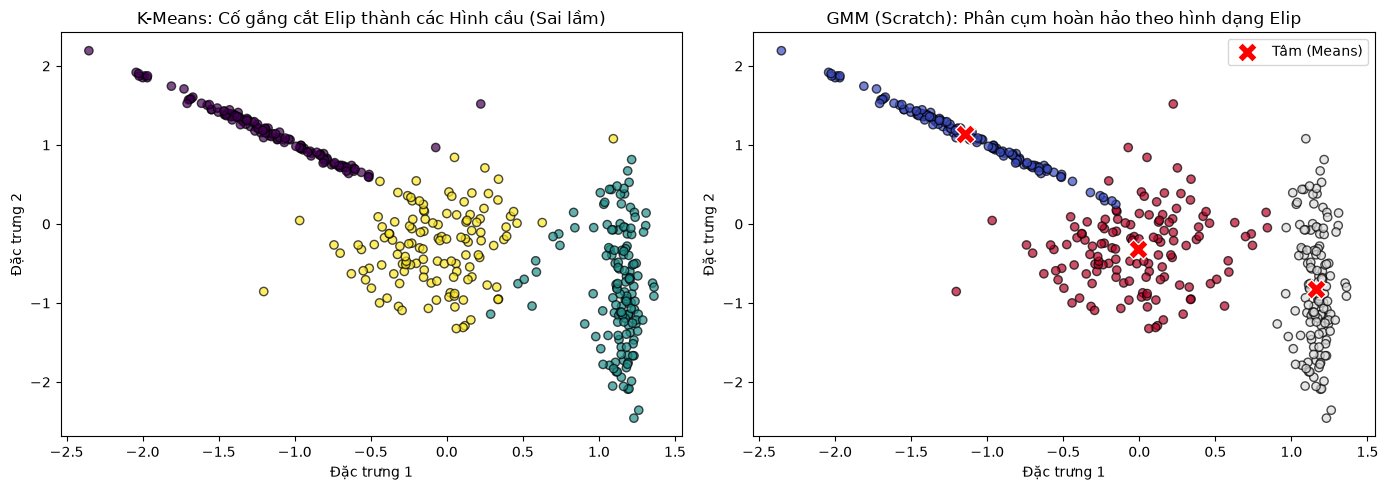

In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from utils.preprocessing import StandardScaler

# 1. Sinh dữ liệu 3 cụm có hình Elip bị bóp méo (K-Means sẽ thảm bại, GMM sẽ chiến thắng)
np.random.seed(42)
n_samples = 400
# Cụm 1: Hình cầu
X1 = np.random.randn(n_samples // 3, 2)
# Cụm 2: Hình Elip dẹt, chéo
X2 = np.dot(np.random.randn(n_samples // 3, 2), [[-0.8, 0.5], [0.8, -0.6]]) + np.array([-3, 3])
# Cụm 3: Hình Elip dài, đứng
X3 = np.dot(np.random.randn(n_samples // 3, 2), [[0.2, 0.0], [0.0, 1.5]]) + np.array([3, -1])

X = np.vstack([X1, X2, X3])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Huấn luyện GMM (Scratch)
t0 = time.time()
model_scratch = GMMScratch(n_components=3).fit(X_scaled)
labels_scratch = model_scratch.predict(X_scaled)
t_scratch = (time.time() - t0) * 1000

# 3. Huấn luyện GMM (Sklearn)
t0 = time.time()
model_sklearn = GaussianMixture(n_components=3, random_state=42).fit(X_scaled)
t_sklearn = (time.time() - t0) * 1000

# Chạy K-Means để đối chiếu sự thất bại với hình Elip
kmeans_labels = KMeans(n_clusters=3, random_state=42, n_init="auto").fit_predict(X_scaled)

# 4. Trực quan hóa so sánh sự mềm dẻo của GMM
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Đồ thị 1: K-Means (Bị giới hạn bởi hình cầu)
ax1.scatter(X_scaled[:, 0], X_scaled[:, 1], c=kmeans_labels, cmap='viridis', edgecolors='k', alpha=0.7)
ax1.set_title("K-Means: Cố gắng cắt Elip thành các Hình cầu (Sai lầm)")
ax1.set_xlabel("Đặc trưng 1")
ax1.set_ylabel("Đặc trưng 2")

# Đồ thị 2: GMM (Scratch) - Căn chỉnh hoàn hảo theo hình Elip
ax2.scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels_scratch, cmap='coolwarm', edgecolors='k', alpha=0.7)
# Vẽ 3 tâm của GMM
centers = model_scratch.means
ax2.scatter(centers[:, 0], centers[:, 1], marker='X', s=200, c='red', edgecolor='white', label='Tâm (Means)')
ax2.set_title("GMM (Scratch): Phân cụm hoàn hảo theo hình dạng Elip")
ax2.set_xlabel("Đặc trưng 1")
ax2.set_ylabel("Đặc trưng 2")
ax2.legend()

plt.tight_layout()
plt.show()